# 02 — Core Machine Learning Experiment: Comparing Three Classifiers

**Primary coursework experiment.** This notebook compares Decision Tree, Logistic Regression, and Linear Support Vector Machine (LinearSVC) on the same project-defined recorded-impact classification task. It uses one stratified train/test split and reports accuracy, macro-precision, macro-recall, macro-F1, per-class metrics, and confusion matrices.

The regression and clustering notebooks are supplementary extensions from the proposal; they do not replace the requirement to compare three classification techniques on a common task. Run this notebook from the project root or from the `notebooks` directory.


In [1]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.data_utils import load_dataset, add_local_date_features, add_coordinates, impact_class

df = add_coordinates(add_local_date_features(load_dataset()))
print(f"Dataset shape: {df.shape}")
print("Incident date range:", df["incident_datetime_np"].min(), "to", df["incident_datetime_np"].max())


Dataset shape: (64131, 74)
Incident date range: 2011-04-14 00:00:00+05:45 to 2026-09-27 00:00:00+05:45


## 1. Define the classification target

The target is a **project-defined recorded-impact category**, not an official BIPAD/NDRRMA severity label:
- **High:** any recorded death or missing person; at least 5 injured; at least 100 people affected; or at least 10 infrastructure units destroyed.
- **Moderate:** at least one recorded injury/affected person, affected family, or destroyed infrastructure, but not High.
- **Low:** none of these impact indicators are recorded.

This is a retrospective classification of recorded impacts. Rows where all target-defining impact indicators are missing are left unlabelled and excluded from classifier training/testing. For partially reported records, the rule uses the available recorded indicators; a missing indicator is not evidence that the true impact was zero. The impact fields used to create the target are excluded from model predictors to reduce target leakage.


In [2]:
df["recorded_impact_class"] = df.apply(impact_class, axis=1)
class_counts = df["recorded_impact_class"].value_counts(dropna=False).rename_axis("class").to_frame("records")
display(class_counts)
display(df["recorded_impact_class"].value_counts(normalize=True).round(3).rename("proportion").to_frame())


,records
class,
Moderate,47094
Low,9935
High,7102


,proportion
recorded_impact_class,
Moderate,0.734
Low,0.155
High,0.111


## 2. Prepare predictors and split the data

Predictors are event-context fields: hazard ID, incident date features, coordinates when available, and reporting/verification fields. Human impact and loss fields are intentionally excluded because they define or directly reflect the outcome. The same stratified 80/20 split and preprocessing are used for all three algorithms to make the comparison fair.


In [3]:
context_cols = [
    "hazard", "incident_year", "incident_month", "incident_day_of_year",
    "longitude", "latitude", "verified", "approved", "source", "dataSource"
]
cat_cols = ["hazard", "verified", "approved", "source", "dataSource"]
num_cols = ["incident_year", "incident_month", "incident_day_of_year", "longitude", "latitude"]

model_df = df[context_cols + ["recorded_impact_class"]].dropna(subset=["recorded_impact_class"]).copy()
X = model_df[context_cols]
y = model_df["recorded_impact_class"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

def make_preprocessor():
    return ColumnTransformer([
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_cols),
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler())
        ]), num_cols),
    ])

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Training class proportions:")
display(y_train.value_counts(normalize=True).round(3).rename("proportion").to_frame())


Training rows: 51304 | Test rows: 12827
Training class proportions:


,proportion
recorded_impact_class,
Moderate,0.734
Low,0.155
High,0.111


## 3. Train and compare three classification algorithms

The three required methods are: (1) Decision Tree, (2) Logistic Regression, and (3) Linear Support Vector Machine (LinearSVC). Class weighting is used to mitigate class imbalance. Hyperparameters are stated explicitly and should be described as baseline settings, not as globally optimal values.


In [4]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=50, class_weight="balanced", random_state=42
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=42
    ),
    "Linear SVM": LinearSVC(
        C=1.0, class_weight="balanced", random_state=42, max_iter=5000
    ),
}

results = []
predictions = {}
pipelines = {}
for name, estimator in models.items():
    pipe = Pipeline([("preprocess", make_preprocessor()), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    pipelines[name] = pipe
    predictions[name] = pred
    results.append({
        "algorithm": name,
        "accuracy": accuracy_score(y_test, pred),
        "macro_precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_test, pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_test, pred, average="macro", zero_division=0),
    })

comparison = pd.DataFrame(results).sort_values("macro_f1", ascending=False).reset_index(drop=True)
display(comparison.round(4))
report_dir = ROOT / "reports"
report_dir.mkdir(exist_ok=True)
comparison.to_csv(report_dir / "impact_classification_model_comparison.csv", index=False)
print("Saved reports/impact_classification_model_comparison.csv")


,algorithm,accuracy,macro_precision,macro_recall,macro_f1
0,Linear SVM,0.7628,0.6160,0.6141,0.6149
1,Decision Tree,0.6671,0.5767,0.7078,0.5978
2,Logistic Regression,0.6956,0.5684,0.6579,0.5932


Saved reports/impact_classification_model_comparison.csv


## 4. Per-class evaluation and confusion matrices

Macro-F1 gives each class equal weight and is particularly important if the classes are imbalanced. Read precision and recall for each class alongside overall accuracy. A confusion matrix shows which classes are being confused.



### Decision Tree
              precision    recall  f1-score   support

         Low       0.49      0.78      0.60      1987
    Moderate       0.92      0.64      0.75      9419
        High       0.32      0.71      0.44      1421

    accuracy                           0.67     12827
   macro avg       0.58      0.71      0.60     12827
weighted avg       0.79      0.67      0.70     12827



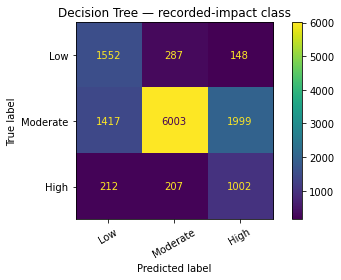


### Logistic Regression
              precision    recall  f1-score   support

         Low       0.45      0.63      0.53      1987
    Moderate       0.89      0.72      0.80      9419
        High       0.36      0.62      0.45      1421

    accuracy                           0.70     12827
   macro avg       0.57      0.66      0.59     12827
weighted avg       0.77      0.70      0.72     12827



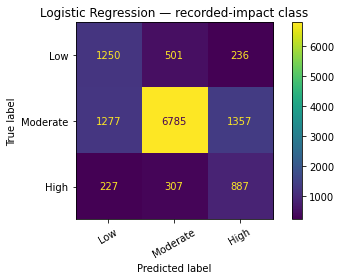


### Linear SVM
              precision    recall  f1-score   support

         Low       0.51      0.49      0.50      1987
    Moderate       0.86      0.86      0.86      9419
        High       0.48      0.49      0.49      1421

    accuracy                           0.76     12827
   macro avg       0.62      0.61      0.61     12827
weighted avg       0.76      0.76      0.76     12827



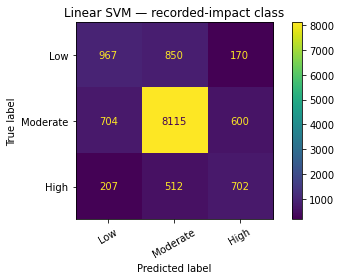

Saved per-class metrics and confusion-matrix counts under reports/.


In [5]:
per_class_rows = []
confusion_rows = []
for name, pred in predictions.items():
    print("\n###", name)
    report = classification_report(
        y_test, pred, labels=["Low", "Moderate", "High"],
        zero_division=0, output_dict=True
    )
    print(classification_report(y_test, pred, labels=["Low", "Moderate", "High"], zero_division=0))
    for label in ["Low", "Moderate", "High"]:
        row = {"algorithm": name, "class": label}
        row.update(report.get(label, {}))
        per_class_rows.append(row)

    cm_display = ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=["Low", "Moderate", "High"],
        xticks_rotation=30, values_format="d"
    )
    plt.title(f"{name} — recorded-impact class")
    plt.tight_layout()
    plt.show()
    cm = cm_display.confusion_matrix
    for i, actual_label in enumerate(["Low", "Moderate", "High"]):
        for j, predicted_label in enumerate(["Low", "Moderate", "High"]):
            confusion_rows.append({
                "algorithm": name,
                "actual_class": actual_label,
                "predicted_class": predicted_label,
                "count": int(cm[i, j]),
            })

pd.DataFrame(per_class_rows).to_csv(report_dir / "impact_classification_per_class.csv", index=False)
pd.DataFrame(confusion_rows).to_csv(report_dir / "impact_classification_confusion_matrices.csv", index=False)
print("Saved per-class metrics and confusion-matrix counts under reports/.")

## 5. Interpretation and limitations

- Select the best baseline using **macro-F1 plus per-class recall**, not accuracy alone. A high score does not establish operational readiness.
- The labels are an explicit research definition and are not an official severity standard.
- The target describes recorded historical impacts. Incomplete reporting may cause an apparently low-impact record to reflect missing information.
- A random split evaluates records sampled from the same extract; a chronological hold-out split would be a stronger test of future-year generalisation.
- Hazard IDs should not be described as hazard names unless an authoritative mapping is supplied.
- The model is for coursework analysis and must not be used for real-time emergency decisions without external validation.

## 6. Supplementary proposal extensions

Use `01_data_quality_and_eda.ipynb` for dataset quality and descriptive analysis, and `03_nlp_title_clustering.ipynb` for exploratory TF-IDF/K-Means title clustering. Linear Regression for reported `estimatedLoss` is included below as a secondary experiment; it is not part of the three-classifier comparison above. Missing loss is excluded rather than replaced by zero, and the currency/unit must be verified before interpreting monetary values.


### Supplementary experiment — Linear Regression for reported economic loss

This optional extension aligns with the proposal's impact-estimation objective. It estimates reported `estimatedLoss` retrospectively, only where the target is present and non-negative. Because this is a skewed target, the model is fitted to `log1p(loss)`; metrics are evaluated after inverse transformation.


In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

reg_df = df.loc[df["estimatedLoss"].notna() & (df["estimatedLoss"] >= 0), context_cols + ["estimatedLoss"]].copy()
Xr = reg_df[context_cols]
yr = np.log1p(reg_df["estimatedLoss"].astype(float))
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)
reg = Pipeline([("preprocess", make_preprocessor()), ("model", LinearRegression())])
reg.fit(Xr_train, yr_train)
pred_log = reg.predict(Xr_test)
y_true = np.expm1(yr_test)
y_hat = np.maximum(0, np.expm1(pred_log))
median_hat = np.full(len(y_true), float(reg_df["estimatedLoss"].median()))
reg_metrics = pd.DataFrame([
    {"model": "Linear Regression (log1p target)", "MAE": mean_absolute_error(y_true, y_hat),
     "RMSE": mean_squared_error(y_true, y_hat) ** 0.5, "R2": r2_score(y_true, y_hat)},
    {"model": "Median baseline", "MAE": mean_absolute_error(y_true, median_hat),
     "RMSE": mean_squared_error(y_true, median_hat) ** 0.5, "R2": r2_score(y_true, median_hat)},
])
display(reg_metrics)
reg_metrics.to_csv(report_dir / "supplementary_loss_regression_metrics.csv", index=False)


,model,MAE,RMSE,R2
0,Linear Regression (log1p target),2.278901e+06,5.964674e+07,-0.001434
1,Median baseline,2.285313e+06,5.964362e+07,-0.001329


**Do not overclaim:** if Linear Regression fails to outperform the median baseline, report that result plainly. A negative original-scale R² means it performs worse than predicting the test-set mean under that metric. This is a retrospective baseline, not pre-disaster forecasting.


## Reproducibility and paper outputs

The standalone runner `scripts/run_paper_experiments.py` reproduces the three classifiers and exports the paper comparison table, per-class metrics, confusion-matrix counts and figures, class distribution, software metadata, and dataset-integrity audit. Run it from the project root with `python scripts/run_paper_experiments.py`. It uses the same target definition, features, random seed (42), stratified 80/20 split, preprocessing and estimator parameters as this notebook.

The target is researcher-defined from reported outcomes; it is not an official BIPAD severity label and must not be interpreted as an early-warning prediction.
